Generation: 0 Best Cost: 1033.58
Generation: 25 Best Cost: 43.68
Generation: 50 Best Cost: 31.7
Generation: 75 Best Cost: 28.05
Generation: 100 Best Cost: 26.21
Generation: 125 Best Cost: 26.21
Generation: 150 Best Cost: 26.2
Generation: 175 Best Cost: 26.2
Generation: 200 Best Cost: 26.2
Generation: 225 Best Cost: 26.2

Best Path:
[(1, 1), [1, 1], [7, 3], [9, 9], [12, 13], [13, 16], (18, 18)]
Total Path Length: 26.2


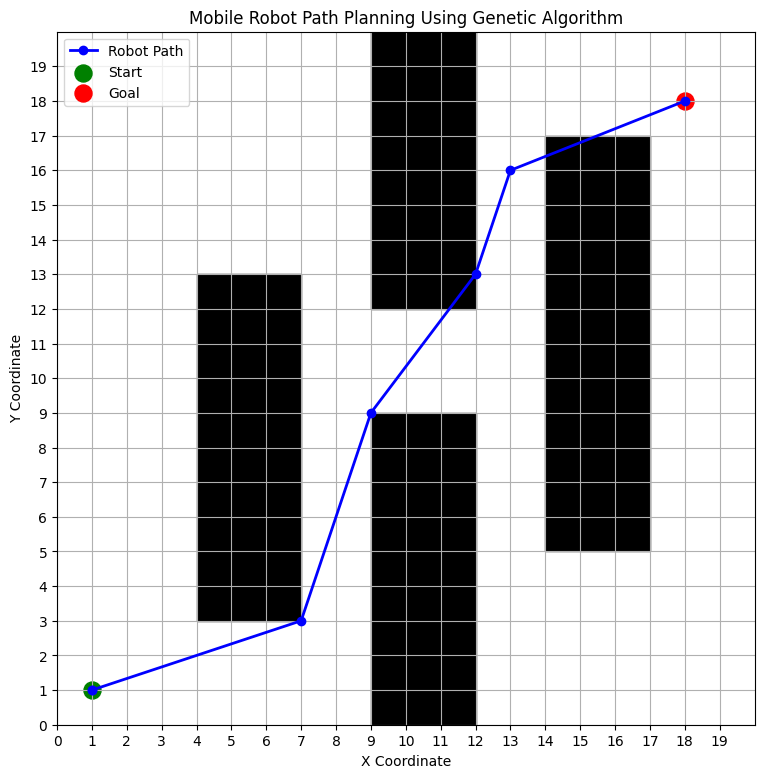

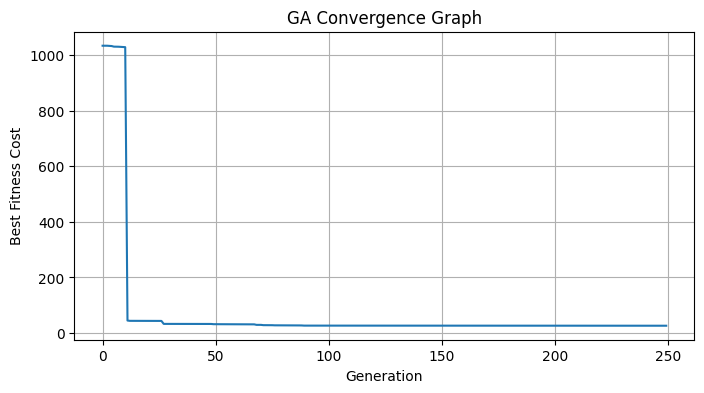

In [2]:

import random
import math
import numpy as np
import matplotlib.pyplot as plt

# Environment
SIZE = 20
START = (1, 1)
GOAL = (18, 18)

# Rectangular obstacles: (x1, y1, x2, y2)
obstacles = [
    (4, 3, 6, 12),
    (9, 0, 11, 8),
    (9, 12, 11, 19),
    (14, 5, 16, 16)
]

POP_SIZE = 120
GENERATIONS = 250
WAYPOINTS = 5
MUTATION_RATE = 0.2
random.seed(42)

# Check whether a point is inside an obstacle
def blocked(x, y):
    for x1, y1, x2, y2 in obstacles:
        if x1 <= x <= x2 and y1 <= y <= y2:
            return True
    return False

# Generate a random valid waypoint
def random_point():
    while True:
        x = random.randint(0, SIZE - 1)
        y = random.randint(0, SIZE - 1)
        if not blocked(x, y):
            return [x, y]

# Create chromosome
def create_path():
    return [random_point() for _ in range(WAYPOINTS)]

# Calculate distance
def distance(a, b):
    return math.dist(a, b)

# Check whether a path segment hits an obstacle
def collision(a, b):
    steps = int(distance(a, b) * 4) + 1

    for i in range(steps + 1):
        t = i / steps
        x = a[0] + t * (b[0] - a[0])
        y = a[1] + t * (b[1] - a[1])

        if blocked(x, y):
            return True

    return False

# Fitness function (lower cost is better)
def fitness(chromosome):
    path = [START] + chromosome + [GOAL]

    total_distance = 0
    penalty = 0

    for i in range(len(path) - 1):
        total_distance += distance(path[i], path[i + 1])

        if collision(path[i], path[i + 1]):
            penalty += 1000

    return total_distance + penalty

# Tournament selection
def selection(population):
    candidates = random.sample(population, 4)
    return min(candidates, key=fitness)

# Crossover
def crossover(p1, p2):
    point = random.randint(1, WAYPOINTS - 1)
    child = p1[:point] + p2[point:]
    return child

# Mutation
def mutation(chromosome):
    for i in range(WAYPOINTS):
        if random.random() < MUTATION_RATE:
            chromosome[i] = random_point()
    return chromosome

# Initialize population
population = [create_path() for _ in range(POP_SIZE)]
best_history = []

# Genetic Algorithm
for generation in range(GENERATIONS):

    population.sort(key=fitness)

    new_population = [population[0]]

    while len(new_population) < POP_SIZE:
        p1 = selection(population)
        p2 = selection(population)

        child = crossover(p1, p2)
        child = mutation(child)

        new_population.append(child)

    population = new_population

    best = fitness(population[0])
    best_history.append(best)

    if generation % 25 == 0:
        print("Generation:", generation,
              "Best Cost:", round(best, 2))

# Best solution
best_path = [START] + population[0] + [GOAL]

print("\nBest Path:")
print(best_path)
print("Total Path Length:",
      round(fitness(population[0]), 2))

# Plot environment and path
plt.figure(figsize=(9, 9))

for x1, y1, x2, y2 in obstacles:
    plt.fill(
        [x1, x2 + 1, x2 + 1, x1],
        [y1, y1, y2 + 1, y2 + 1],
        color="black"
    )

x = [p[0] for p in best_path]
y = [p[1] for p in best_path]

plt.plot(x, y, "b-o", linewidth=2, label="Robot Path")
plt.scatter(*START, color="green", s=150, label="Start")
plt.scatter(*GOAL, color="red", s=150, label="Goal")

plt.xlim(0, SIZE)
plt.ylim(0, SIZE)
plt.xticks(range(SIZE))
plt.yticks(range(SIZE))
plt.grid(True)
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Mobile Robot Path Planning Using Genetic Algorithm")
plt.legend()
plt.show()

# Convergence graph
plt.figure(figsize=(8, 4))
plt.plot(best_history)
plt.xlabel("Generation")
plt.ylabel("Best Fitness Cost")
plt.title("GA Convergence Graph")
plt.grid(True)
plt.show()
